# 04 | Consultas analíticas e gráficos (Gold)

Consulta as tabelas `sod_gold` com **Spark SQL** (no AWS, as mesmas consultas rodam no **Athena**: ver `sql/athena_consultas_analiticas.sql`) e gera os gráficos usados no material executivo, salvos em `docs/graficos/`.

> No Glue Notebook, para exibir um gráfico matplotlib use `%matplot plt` no fim da célula. Os PNGs também podem ser salvos no S3.

In [1]:
# Executar apenas no AWS Glue Notebook (comente ao rodar localmente)
# %idle_timeout 60
# %glue_version 5.0
# %worker_type G.1X
# %number_of_workers 2
# %additional_python_modules matplotlib

In [2]:
# Parâmetros e sessão Spark (funciona no Glue Notebook e localmente)
import os, sys
try:
    from awsglue.context import GlueContext
    from pyspark.context import SparkContext
    IS_GLUE = True
except ImportError:
    IS_GLUE = False

BUCKET = "lab-SEU-ID-AQUI"   # <-- AJUSTE: bucket criado no AWS Academy (ex.: lab-123456789012)

if IS_GLUE:
    glue_context = GlueContext(SparkContext.getOrCreate())
    spark = glue_context.spark_session
    BASE = f"s3://{BUCKET}"
else:
    from pyspark.sql import SparkSession
    ROOT = os.path.abspath("..")          # notebook roda a partir de notebooks/
    spark = (SparkSession.builder.appName("tech-challenge-fase3").master("local[*]")
             .config("spark.sql.warehouse.dir", os.path.join(ROOT, "data_lake", "_warehouse"))
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    BASE = os.path.join(ROOT, "data_lake")
print("Ambiente:", "AWS Glue" if IS_GLUE else "local", "| BASE =", BASE)

26/11/02 17:10:55 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/02 17:10:55 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/02 17:10:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Ambiente: local | BASE = /home/claude/tc3/data_lake


### Registro das tabelas Gold
No Glue as tabelas já estão no Data Catalog (`sod_gold.*`). Localmente, registramos as mesmas tabelas a partir dos arquivos Parquet.

In [3]:
import os
GOLD = ["gold_resumo_edicao", "gold_perfil_mercado", "gold_salario", "gold_salario_distribuicao",
        "gold_diversidade_genero", "gold_tecnologias", "gold_ia_adocao", "gold_ia_empresa"]
if not IS_GLUE:
    spark.sql("CREATE DATABASE IF NOT EXISTS sod_gold")
    for t in GOLD:
        spark.sql(f"CREATE TABLE IF NOT EXISTS sod_gold.{t} USING parquet LOCATION '{os.path.join(BASE, 'gold', t)}'")
spark.sql("SHOW TABLES IN sod_gold").show(truncate=False)

def q(sql):
    """Executa SQL no Spark e devolve pandas (tabelas Gold são pequenas)."""
    return spark.sql(sql).toPandas()

+---------+-------------------------+-----------+
|namespace|tableName                |isTemporary|
+---------+-------------------------+-----------+
|sod_gold |gold_diversidade_genero  |false      |
|sod_gold |gold_ia_adocao           |false      |
|sod_gold |gold_ia_empresa          |false      |
|sod_gold |gold_perfil_mercado      |false      |
|sod_gold |gold_resumo_edicao       |false      |
|sod_gold |gold_salario             |false      |
|sod_gold |gold_salario_distribuicao|false      |
|sod_gold |gold_tecnologias         |false      |
+---------+-------------------------+-----------+



In [4]:
import matplotlib
import matplotlib.pyplot as plt
OUT = "../docs/graficos" if not IS_GLUE else "/tmp/graficos"
os.makedirs(OUT, exist_ok=True)
COR = {"ink": "#102A33", "petrol": "#0F5C6E", "teal": "#2A9D8F", "amber": "#E9A23B", "coral": "#D1495B", "grey": "#8A9BA3"}
ED = {"2023": "2023", "2024_2025": "2024-25", "2025_2026": "2025-26"}
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110})

def salvar(fig, nome):
    fig.tight_layout(); fig.savefig(f"{OUT}/{nome}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Painel executivo por edição

In [5]:
kpis = q("SELECT * FROM sod_gold.gold_resumo_edicao ORDER BY edicao")
kpis

,edicao,respondentes,pct_feminino,pct_remoto,pct_usa_ia,pct_empresa_paga_ia,pct_setor_financeiro,pct_sudeste,faixa_mediana,pct_acima_16k
0,2023,5293,24.43,46.31,80.28,6.36,19.50,61.39,8-12k,16.25
1,2024_2025,5215,23.49,45.69,93.48,19.27,21.29,61.72,8-12k,21.89
2,2025_2026,3494,21.95,39.70,97.91,42.33,18.53,64.41,8-12k,26.99


## 2. Como está estruturado o mercado brasileiro de dados?

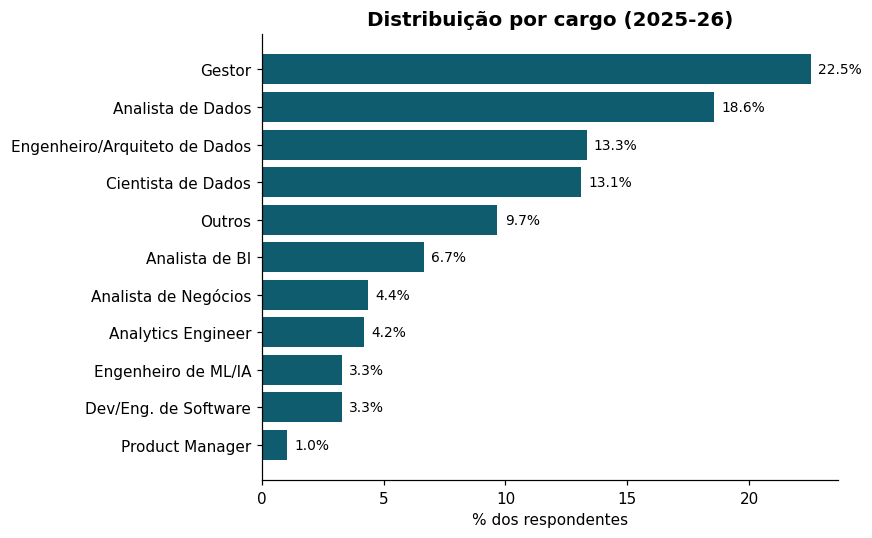

In [6]:
cargo = q("""SELECT categoria, pct FROM sod_gold.gold_perfil_mercado
             WHERE dimensao = 'cargo' AND edicao = '2025_2026' ORDER BY pct""")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cargo.categoria, cargo.pct, color=COR["petrol"])
for y, v in enumerate(cargo.pct): ax.text(v + .3, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Distribuição por cargo (2025-26)"); ax.set_xlabel("% dos respondentes")
salvar(fig, "01_cargos_2025")

In [7]:
setor = q("""SELECT categoria, edicao, pct FROM sod_gold.gold_perfil_mercado
             WHERE dimensao = 'setor'""").pivot(index="categoria", columns="edicao", values="pct")
setor.sort_values("2025_2026", ascending=False).head(6).round(1)

edicao,2023,2024_2025,2025_2026
categoria,,,
Finanças ou Bancos,19.5,21.3,18.5
Tecnologia/Fábrica de Software,18.0,19.4,17.4
Área de Consultoria,8.2,7.3,8.8
Outra Opção,7.2,6.8,7.5
Indústria,6.6,6.8,7.3
Varejo,8.2,7.8,5.6


## 3. Quais perfis são mais valorizados?
Faixa salarial mediana e % que ganha acima de R$ 16 mil/mês (base: quem informou faixa e mora no Brasil).

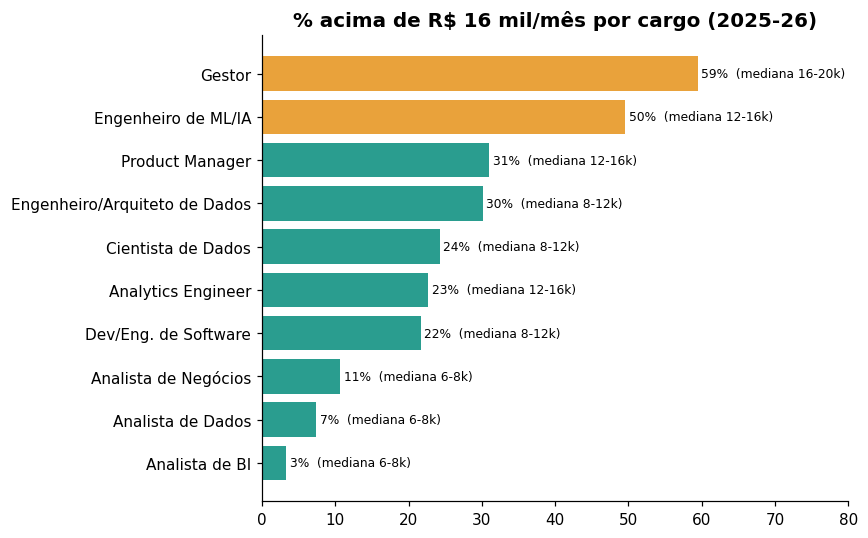

In [8]:
sal = q("""SELECT categoria, pct_acima_16k, faixa_mediana FROM sod_gold.gold_salario
           WHERE dimensao = 'cargo' AND edicao = '2025_2026' AND categoria <> 'Outros'
           ORDER BY pct_acima_16k""")
fig, ax = plt.subplots(figsize=(8, 5))
cores = [COR["amber"] if c in ("Engenheiro de ML/IA", "Gestor") else COR["teal"] for c in sal.categoria]
ax.barh(sal.categoria, sal.pct_acima_16k, color=cores)
for y, (v, f) in enumerate(zip(sal.pct_acima_16k, sal.faixa_mediana)): ax.text(v + .5, y, f"{v:.0f}%  (mediana {f})", va="center", fontsize=8)
ax.set_title("% acima de R$ 16 mil/mês por cargo (2025-26)"); ax.set_xlim(0, 80)
salvar(fig, "02_salario_cargo_2025")

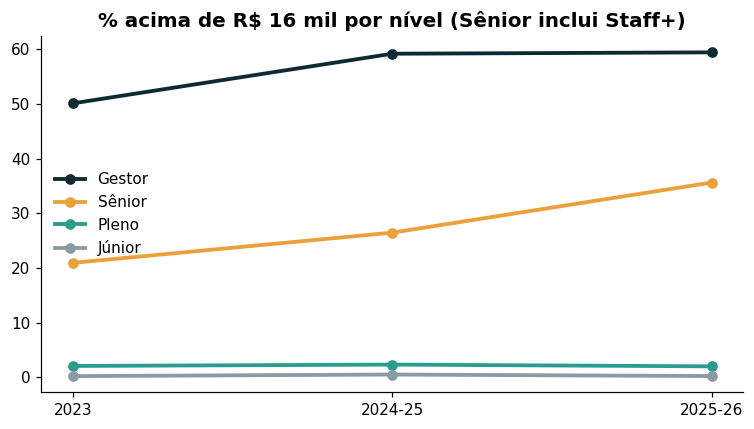

In [9]:
sen = q("""SELECT categoria, edicao, pct_acima_16k FROM sod_gold.gold_salario
           WHERE dimensao = 'nivel_comparavel'""").pivot(index="edicao", columns="categoria", values="pct_acima_16k")
fig, ax = plt.subplots(figsize=(7, 4))
for c, cor in [("Gestor", COR["ink"]), ("Sênior", COR["amber"]), ("Pleno", COR["teal"]), ("Júnior", COR["grey"])]:
    ax.plot([ED[e] for e in sen.index], sen[c], marker="o", lw=2.5, color=cor, label=c)
ax.set_title("% acima de R$ 16 mil por nível (Sênior inclui Staff+)"); ax.legend(frameon=False)
salvar(fig, "03_salario_nivel_evolucao")

## 4. Diversidade de gênero

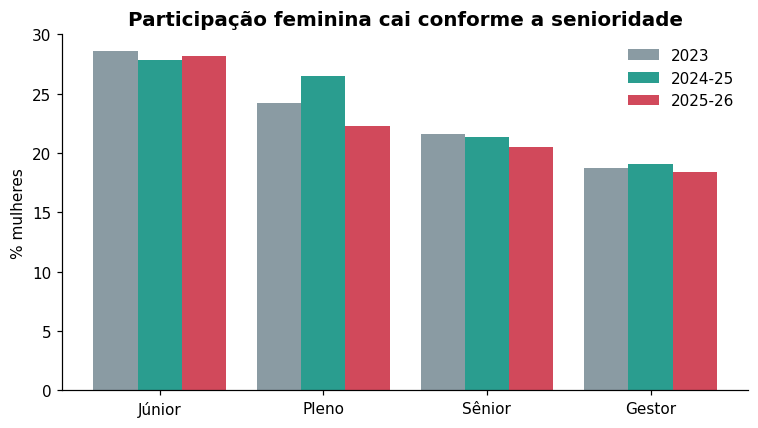

,edicao,categoria,faixa_mediana,pct_acima_16k
0,2023,Sênior | Feminino,8-12k,12.09
1,2023,Sênior | Masculino,12-16k,23.26
2,2024_2025,Sênior | Feminino,8-12k,16.76
3,2024_2025,Sênior | Masculino,12-16k,29.17
4,2025_2026,Sênior | Feminino,12-16k,24.47
5,2025_2026,Sênior | Masculino,12-16k,38.52


In [10]:
div = q("""SELECT categoria, edicao, pct_feminino FROM sod_gold.gold_diversidade_genero
           WHERE dimensao = 'nivel_comparavel'""").pivot(index="categoria", columns="edicao", values="pct_feminino")
div = div.loc[["Júnior", "Pleno", "Sênior", "Gestor"]]
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(div)); w = .27
for i, (e, cor) in enumerate(zip(div.columns, [COR["grey"], COR["teal"], COR["coral"]])):
    ax.bar([p + (i - 1) * w for p in x], div[e], w, color=cor, label=ED[e])
ax.set_xticks(list(x)); ax.set_xticklabels(div.index); ax.set_ylabel("% mulheres")
ax.set_title("Participação feminina cai conforme a senioridade"); ax.legend(frameon=False)
salvar(fig, "04_mulheres_por_nivel")
q("""SELECT edicao, categoria, faixa_mediana, pct_acima_16k FROM sod_gold.gold_salario
     WHERE dimensao = 'genero_nivel' AND categoria LIKE 'Sênior |%' ORDER BY edicao, categoria""")

## 5. Tecnologias com maior adoção

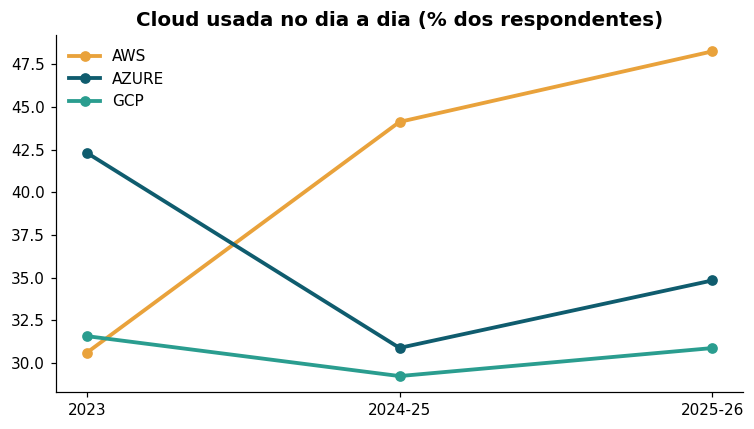

,grupo,tecnologia,pct
0,Banco de dados,postgresql,36.80
1,Banco de dados,sql_server,33.51
2,Banco de dados,databricks,32.89
3,Banco de dados,s3,28.83
4,Banco de dados,mysql,28.54
5,Cloud,aws,48.26
6,Cloud,azure,34.84
7,Cloud,gcp,30.88
8,Cloud,on_premise,14.32
9,Cloud,cloud_propria,5.44


In [11]:
cloud = q("""SELECT tecnologia, edicao, pct FROM sod_gold.gold_tecnologias
             WHERE grupo = 'Cloud' AND tecnologia IN ('aws', 'azure', 'gcp')""").pivot(index="edicao", columns="tecnologia", values="pct")
fig, ax = plt.subplots(figsize=(7, 4))
for c, cor in [("aws", COR["amber"]), ("azure", COR["petrol"]), ("gcp", COR["teal"])]:
    ax.plot([ED[e] for e in cloud.index], cloud[c], marker="o", lw=2.5, color=cor, label=c.upper())
ax.set_title("Cloud usada no dia a dia (% dos respondentes)"); ax.legend(frameon=False)
salvar(fig, "05_cloud_evolucao")
q("""SELECT grupo, tecnologia, pct FROM (
       SELECT grupo, tecnologia, pct, ROW_NUMBER() OVER (PARTITION BY grupo ORDER BY pct DESC) AS r
       FROM sod_gold.gold_tecnologias WHERE edicao = '2025_2026' AND tecnologia <> 'nenhuma') t
     WHERE r <= 5 ORDER BY grupo, pct DESC""")

## 6. Adoção de IA generativa e seu impacto

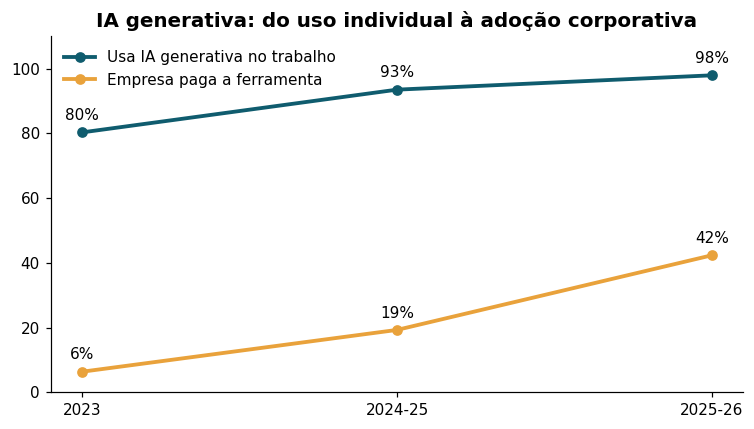

In [12]:
ia = q("""SELECT edicao, pct_usa_ia, pct_empresa_paga FROM sod_gold.gold_ia_adocao
          WHERE dimensao = 'total' ORDER BY edicao""")
fig, ax = plt.subplots(figsize=(7, 4))
x = [ED[e] for e in ia.edicao]
ax.plot(x, ia.pct_usa_ia, marker="o", lw=2.5, color=COR["petrol"], label="Usa IA generativa no trabalho")
ax.plot(x, ia.pct_empresa_paga, marker="o", lw=2.5, color=COR["amber"], label="Empresa paga a ferramenta")
for xi, a, b in zip(x, ia.pct_usa_ia, ia.pct_empresa_paga):
    ax.annotate(f"{a:.0f}%", (xi, a), textcoords="offset points", xytext=(0, 8), ha="center")
    ax.annotate(f"{b:.0f}%", (xi, b), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_ylim(0, 110); ax.set_title("IA generativa: do uso individual à adoção corporativa"); ax.legend(frameon=False)
salvar(fig, "06_ia_adocao")

edicao                     2023  2024_2025  2025_2026
categoria                                            
Empresa paga a ferramenta  17.6       18.7       25.2
Não usa IA                  7.9        9.5       14.0
Usa por conta própria       7.8       10.5       12.7


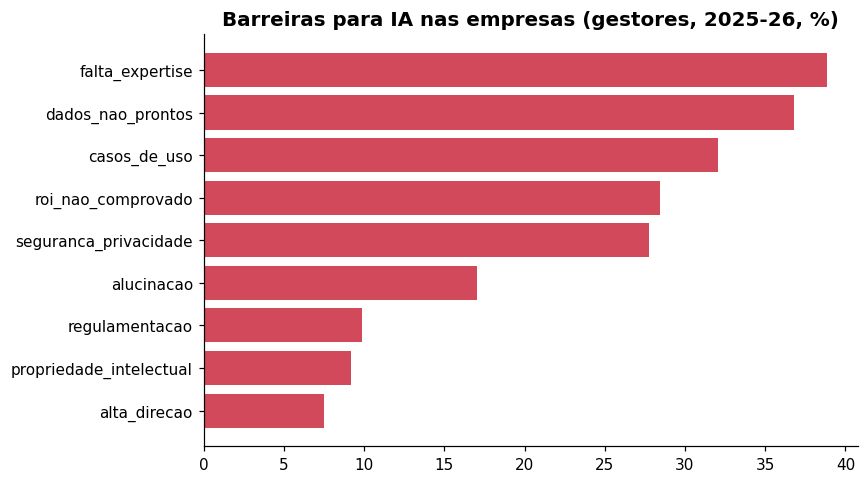

In [13]:
imp = q("""SELECT categoria, edicao, pct_acima_16k FROM sod_gold.gold_salario
           WHERE dimensao = 'perfil_uso_ia'""").pivot(index="categoria", columns="edicao", values="pct_acima_16k")
print(imp.round(1))
bar = q("""SELECT categoria, edicao, pct FROM sod_gold.gold_ia_empresa
           WHERE indicador = 'barreira'""").pivot(index="categoria", columns="edicao", values="pct")
bar = bar.sort_values("2025_2026")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(bar.index, bar["2025_2026"], color=COR["coral"])
ax.set_title("Barreiras para IA nas empresas (gestores, 2025-26, %)")
salvar(fig, "07_ia_barreiras")

## 7. Diferenças por região e modelo de trabalho

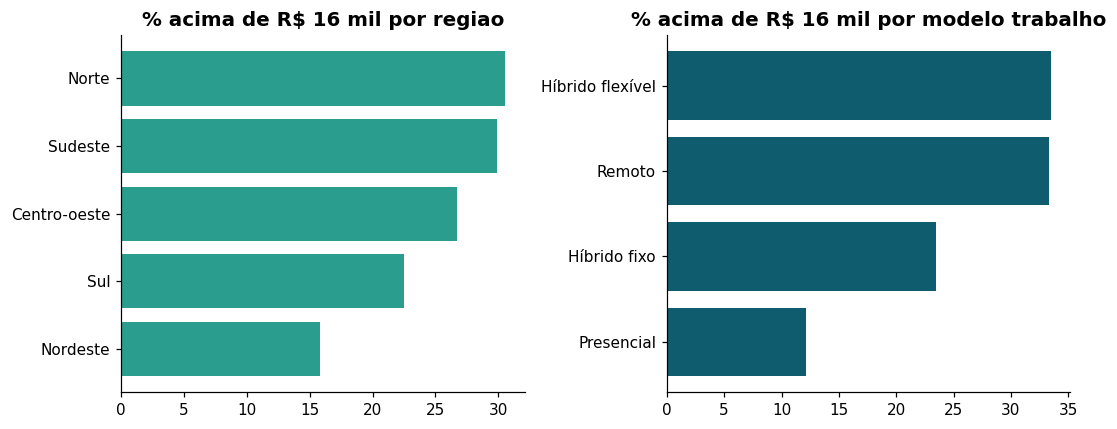

,edicao,dimensao,categoria,pct
0,2025_2026,modelo_ideal,Híbrido fixo,13.05
1,2025_2026,modelo_trabalho,Híbrido fixo,19.99
2,2025_2026,modelo_ideal,Híbrido flexível,42.98
3,2025_2026,modelo_trabalho,Híbrido flexível,19.55
4,2025_2026,modelo_ideal,Presencial,1.86
5,2025_2026,modelo_trabalho,Presencial,20.76
6,2025_2026,modelo_ideal,Remoto,42.11
7,2025_2026,modelo_trabalho,Remoto,39.70


In [14]:
rm = q("""SELECT dimensao, categoria, pct_acima_16k, faixa_mediana FROM sod_gold.gold_salario
          WHERE dimensao IN ('regiao', 'modelo_trabalho') AND edicao = '2025_2026' ORDER BY dimensao, pct_acima_16k""")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, d, cor in [(axes[0], "regiao", COR["teal"]), (axes[1], "modelo_trabalho", COR["petrol"])]:
    t = rm[rm.dimensao == d]
    ax.barh(t.categoria, t.pct_acima_16k, color=cor); ax.set_title(f"% acima de R$ 16 mil por {d.replace('_', ' ')}")
salvar(fig, "08_regiao_modelo")
q("""SELECT edicao, dimensao, categoria, pct FROM sod_gold.gold_perfil_mercado
     WHERE dimensao IN ('modelo_trabalho', 'modelo_ideal') AND edicao = '2025_2026' ORDER BY categoria, dimensao""")